In [1]:
import pandas as pd
import os
import re
import periodictable

In [2]:
simbolos_elementos = [element.symbol for element in periodictable.elements if element.symbol][1:]

In [3]:
dfs = []

for arquivo in os.listdir('../Data/'):
    if arquivo.endswith('.xls'):
        caminho_arquivo = os.path.join('../Data/', arquivo)
        
        df_temporario = pd.read_excel(caminho_arquivo)
        
        dfs.append(df_temporario)

df = pd.concat(dfs, ignore_index=True)

___

In [50]:
list_total_elements = []
list_perovskites = []

c = 1
x = 0
pattern = re.compile(r'\b(?:[A-Z][a-z]?(?:\d+(?:\.\d*)?|\.\d+)?){2}[A-Z][a-z]?(?:\d+(?:\.\d*)?|\.\d+)?3\b')

for abstract in df['Abstract'].dropna():
    len_pero = len(list_perovskites)
    abstract = str(abstract)
    matches = re.findall(pattern, abstract)
    matches = set(matches)
    if matches:
        for match in matches:
            elementos = re.findall(r'[A-Z][a-z]*', match)
            if all(elemento in simbolos_elementos for elemento in elementos):
                list_perovskites.append(match)
                x += 1
                print(f'{x}. No artigo n°{c} foi encontrada a perovskita {match}, com os elementos: {elementos}')
                for elemento in elementos:
                    list_total_elements.append(elemento)
        #print(c, matches, '\n')
        if len(list_perovskites) > len_pero:   #### Só para pular linha
            print()                            ####
    c += 1

1. No artigo n°11 foi encontrada a perovskita CsPbBr3, com os elementos: ['Cs', 'Pb', 'Br']

2. No artigo n°14 foi encontrada a perovskita BaTiO3, com os elementos: ['Ba', 'Ti', 'O']

3. No artigo n°18 foi encontrada a perovskita CsBCl3, com os elementos: ['Cs', 'B', 'Cl']

4. No artigo n°19 foi encontrada a perovskita Bi0.5TiO3, com os elementos: ['Bi', 'Ti', 'O']

5. No artigo n°24 foi encontrada a perovskita CsPbBr3, com os elementos: ['Cs', 'Pb', 'Br']

6. No artigo n°25 foi encontrada a perovskita CsSnI3, com os elementos: ['Cs', 'Sn', 'I']

7. No artigo n°26 foi encontrada a perovskita SrTiO3, com os elementos: ['Sr', 'Ti', 'O']

8. No artigo n°28 foi encontrada a perovskita CsPbI3, com os elementos: ['Cs', 'Pb', 'I']

9. No artigo n°30 foi encontrada a perovskita BaMoO3, com os elementos: ['Ba', 'Mo', 'O']
10. No artigo n°30 foi encontrada a perovskita SrHfO3, com os elementos: ['Sr', 'Hf', 'O']

11. No artigo n°34 foi encontrada a perovskita CsNbO3, com os elementos: ['Cs', 'Nb

In [52]:
for i in df['Abstract']:
    if 'KNN3' in str(i):
        print(i)

Ecological-friendly and unhazardous materials are being prepared by the scientific community in search of novel lead-free ferroelectric materials. K0.5Na0.5NbO3belonging to the ABO3 perovskite was found to be promising ferroelectric lead-free material. A new set of compound, namely, double dopant LKNZN compound was prepared by solid state route. Here, Lithium is partially replaced with Sodium, at A-site, and Zirconium substituted with Niobium, at B-site. The compositional formula of the present investigations is: [((K0.5Na0.5)(1-x)Lix) (Zr0.025Nb0.98)O3], where x=0, and 0.025 9 (labelled as KNN1 and KNN2). In addition we have prepared (K0.5(Na0.475Li0.025)) (Zr0.025Nb0.98)O3 (labelled as KNN3). XRD patterns obtained at room temperaturehave shown maximum intensity peak of (111), confirms the formation of a single-phase. SEM pictures of KNN1 and KNN2 have shown cubical grain with bimodal grain distribution, whereas KNN3 consist of circular bimodal grain distribution. Delectric measuremen

___

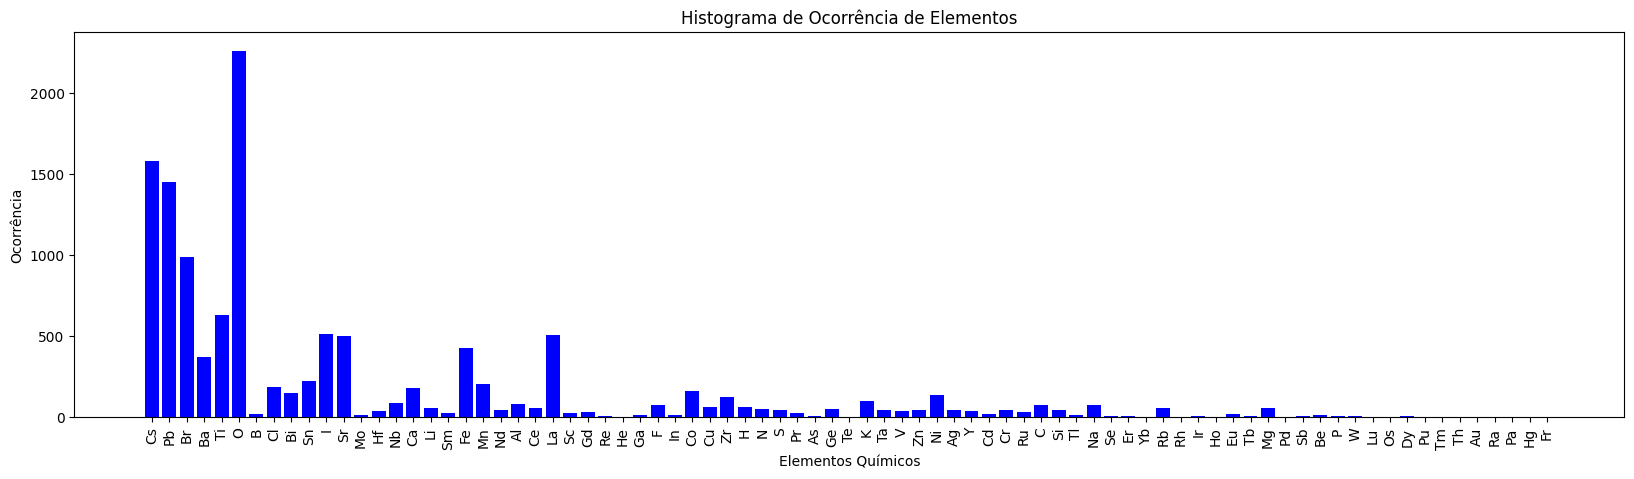

In [46]:
import matplotlib.pyplot as plt
from collections import Counter

contagem_elementos = Counter(list_total_elements)

elementos, contagens = zip(*contagem_elementos.items())

plt.figure(figsize=(20,5))
plt.bar(elementos, contagens, color='blue')
plt.xlabel('Elementos Químicos')
plt.ylabel('Ocorrência')
plt.title('Histograma de Ocorrência de Elementos')
plt.xticks(rotation=90)
plt.show()

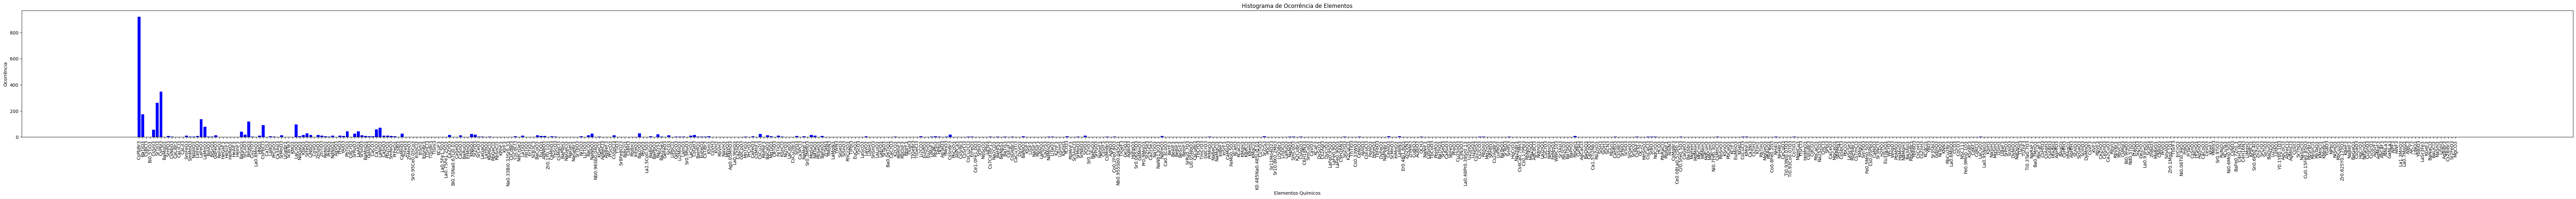

In [47]:
contagem_elementos = Counter(list_perovskites)

elementos, contagens = zip(*contagem_elementos.items())

plt.figure(figsize=(100,5))
plt.bar(elementos, contagens, color='blue')
plt.xlabel('Elementos Químicos')
plt.ylabel('Ocorrência')
plt.title('Histograma de Ocorrência de Elementos')
plt.xticks(rotation=90)
plt.show()

___

# Spacy

In [19]:
import spacy
nlp = spacy.load('en_core_web_sm')

from spacy import displacy

In [20]:
for c, abstract in enumerate(df['Abstract']):
    doc = nlp(abstract)
    #print([sent for sent in doc.sents])
    for sent in doc.sents:
        doc = nlp(str(sent))
        #print([t for t in doc if not t.is_stop])
        #print([t for t in doc])
        #print([(t.text, t.lemma_) for t in doc])
        #print([(t.text, t.pos_) for t in doc])
        #print([(t.text, t.tag_) for t in doc])
        displacy.render(doc, style='ent', jupyter=True)
        #displacy.render(doc, style='dep', jupyter=True)
        #print(doc.text)
    print('---------------')
    if c >= 5:
        break

c:\Users\pedro220045\.conda\envs\pepepy_filho\Lib\site-packages\spacy\displacy\__init__.py:213: UserWarning: [W006] No entities to visualize found in Doc object. If this is surprising to you, make sure the Doc was processed using a model that supports named entity recognition, and check the `doc.ents` property manually if necessary.
  warnings.warn(Warnings.W006)


---------------


---------------


---------------


---------------


---------------


---------------
